# Исследование данных (EDA)

В данной работе используется датасет Rain in Australia.
Цель исследования — изучить зависимости между погодными
условиями и наличием дождя на следующий день.

Целевая переменная — `RainTomorrow`:
- `Yes` — на следующий день был дождь;
- `No` — на следующий день дождя не было.

## Гипотезы

1. Если убрать признаки ветра, модель будет предсказывать лучше.
2. Если заполнять пропуски средним вместо медианы, модель будет работать хуже.
3. `LogisticRegression` будет предсказывать лучше `RandomForest`.
4. Если увеличить `min_samples_leaf` у `RandomForest`, качество модели улучшится.
5. Если уделять больше внимания классу `RainTomorrow = Yes` с помощью `class_weight='balanced'`, модель будет лучше находить дождливые дни.

Выводы по каждой гипотезе (подтвердилась / не подтвердилась / частично и почему) будут записаны после экспериментов.

## 1. EDA

### 1.1. Первичный анализ данных

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

table = pd.read_csv("weatherAUS.csv")

# Размер таблицы
print("Размер таблицы:", table.shape)

# Названия столбцов
print("Названия столбцов:", list(table.columns))

# Типы данных
print("Типы данных:")
print(table.dtypes)

# Количество дубликатов
print("Количество дубликатов:", table.duplicated().sum())

# Количество пропусков в каждом столбце
print("Пропуски в каждом столбце:")
print(table.isna().sum().sort_values())

# Распределение целевой переменной
print("Распределение RainTomorrow:")
print(table["RainTomorrow"].value_counts(normalize=True))

# Временной диапазон данных
print("Первая дата:", pd.to_datetime(table["Date"]).min())
print("Последняя дата:", pd.to_datetime(table["Date"]).max())

# Количество уникальных значений в столбцах
print("Количество уникальных значений:")
print(table.nunique())


Размер таблицы: (145460, 23)
Названия столбцов: ['Date', 'Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday', 'RainTomorrow']
Типы данных:
Date                 str
Location             str
MinTemp          float64
MaxTemp          float64
Rainfall         float64
Evaporation      float64
Sunshine         float64
WindGustDir          str
WindGustSpeed    float64
WindDir9am           str
WindDir3pm           str
WindSpeed9am     float64
WindSpeed3pm     float64
Humidity9am      float64
Humidity3pm      float64
Pressure9am      float64
Pressure3pm      float64
Cloud9am         float64
Cloud3pm         float64
Temp9am          float64
Temp3pm          float64
RainToday            str
RainTomorrow         str
dtype: object
Количество дубликатов: 0
Пропуски в каждо

### 1.2. Пропуски, баланс классов, корреляции, распределения

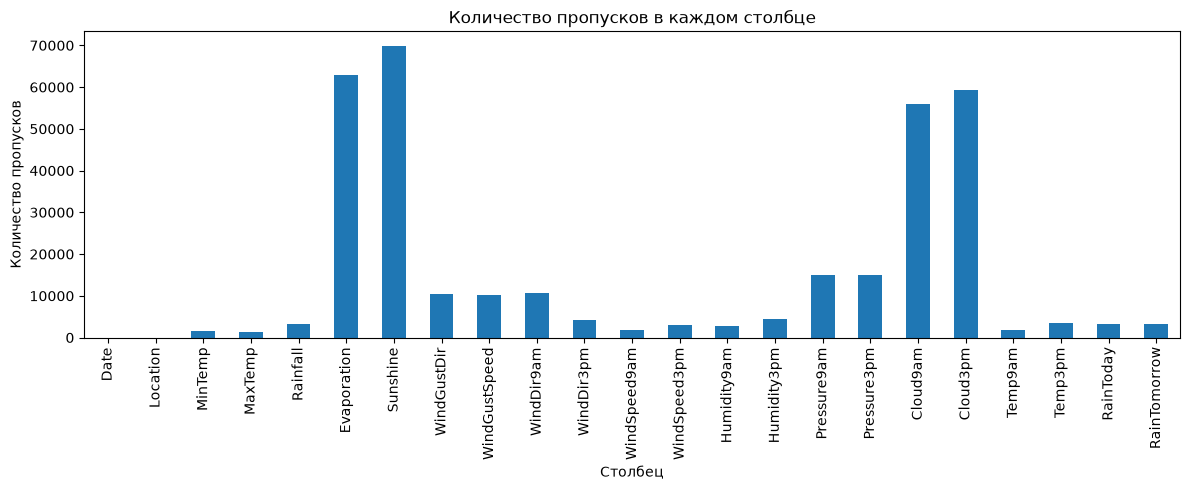

RainTomorrow
No     77.6
Yes    22.4
Name: proportion, dtype: float64


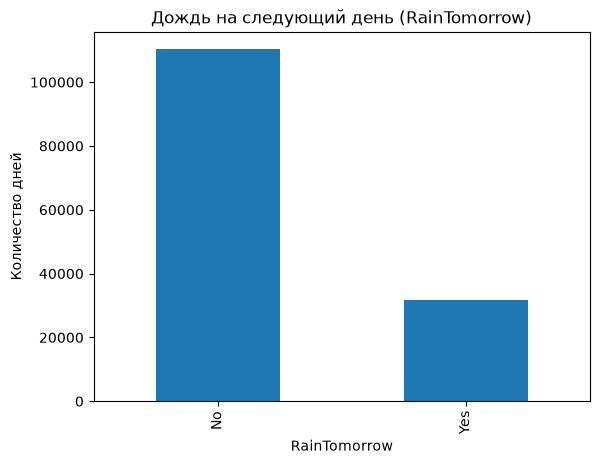

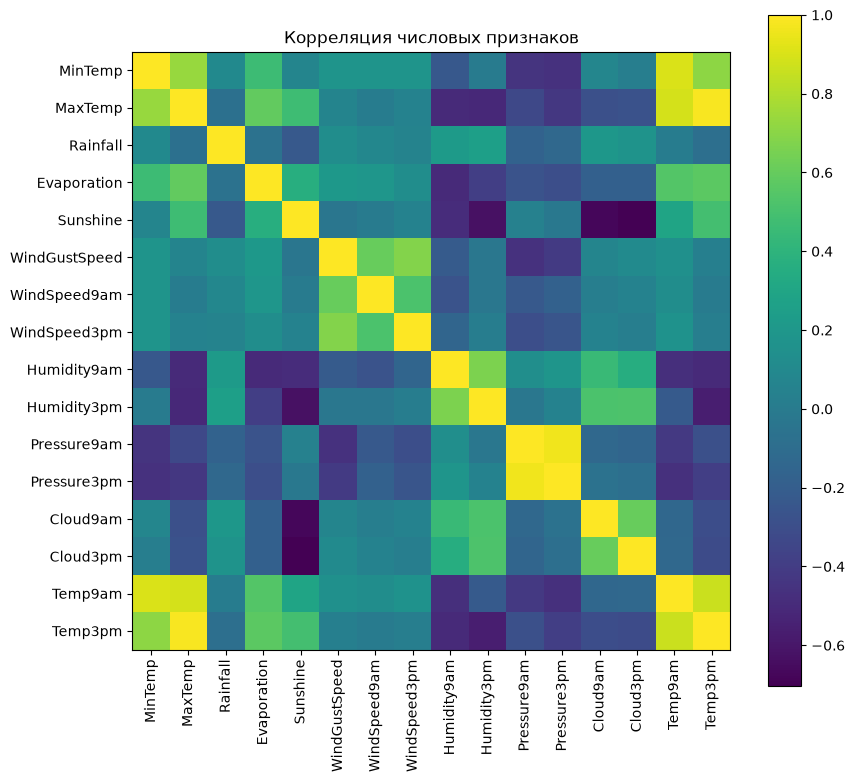

Самая сильная положительная: ('MaxTemp', 'Temp3pm') 0.985
Самая сильная отрицательная: ('Sunshine', 'Cloud3pm') -0.704


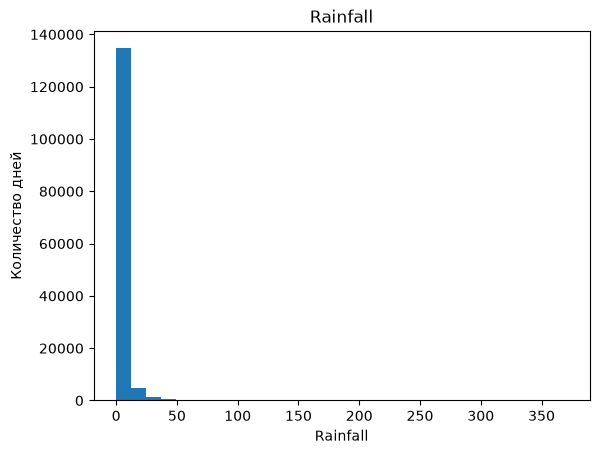

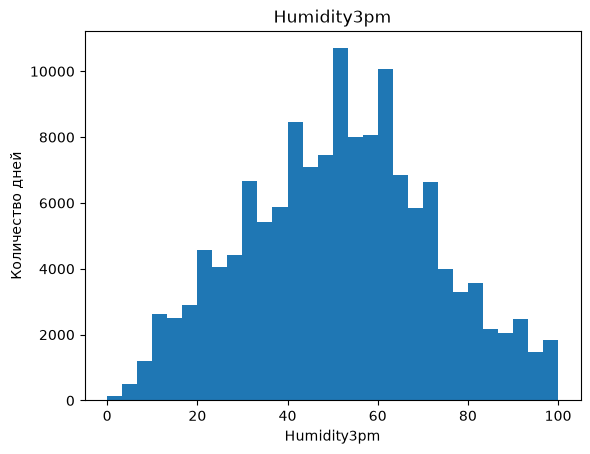

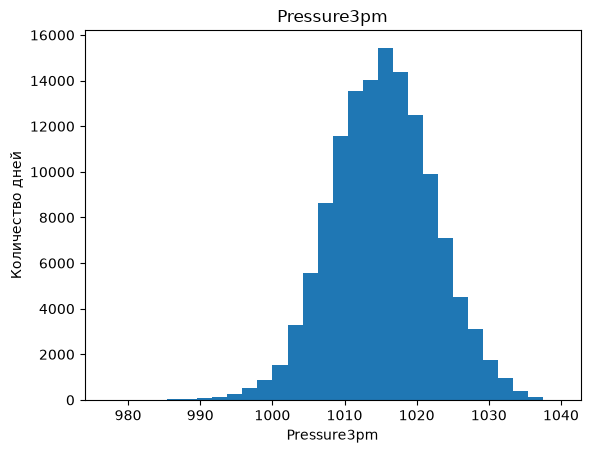

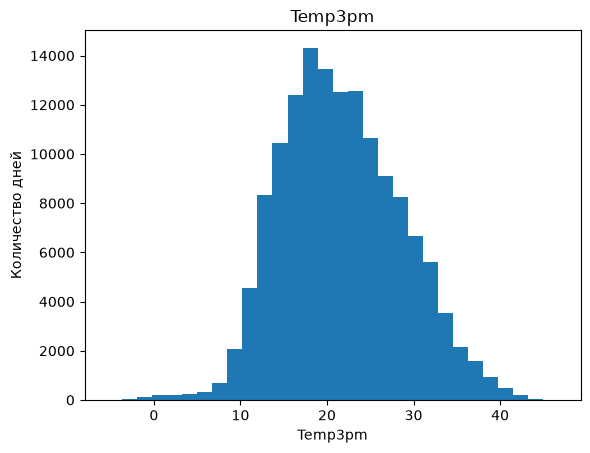

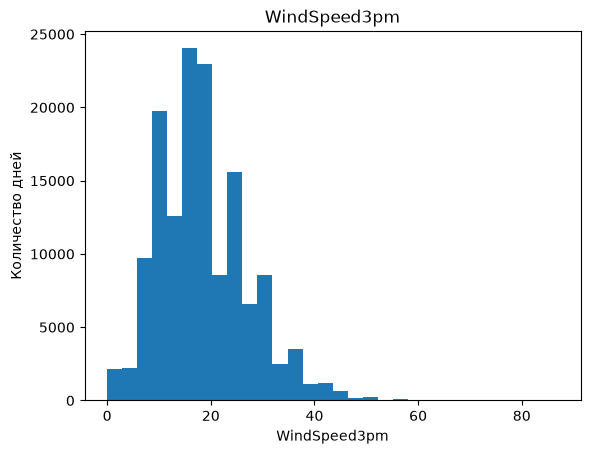

In [2]:
# пропуски по столбцам
plt.figure(figsize=(12, 5))
table.isna().sum().plot(kind="bar")
plt.title("Количество пропусков в каждом столбце")
plt.xlabel("Столбец")
plt.ylabel("Количество пропусков")
plt.tight_layout()
plt.show()

# баланс классов
print((table["RainTomorrow"].value_counts(normalize=True) * 100).round(1))
table["RainTomorrow"].value_counts().plot(kind="bar")
plt.title("Дождь на следующий день (RainTomorrow)")
plt.xlabel("RainTomorrow")
plt.ylabel("Количество дней")
plt.show()

# корреляция числовых признаков
matrCor = table.select_dtypes(include="number").corr()
plt.figure(figsize=(9, 8))
plt.imshow(matrCor)
plt.colorbar()
plt.xticks(range(len(matrCor.columns)), matrCor.columns, rotation=90)
plt.yticks(range(len(matrCor.columns)), matrCor.columns)
plt.title("Корреляция числовых признаков")
plt.tight_layout()
plt.show()

# самая сильная положительная и отрицательная связь между признаками
mask = np.triu(np.ones(matrCor.shape), k=1)
pairs = matrCor.where(mask == 1).stack().dropna().sort_values()
print("Самая сильная положительная:", pairs.index[-1], round(pairs.iloc[-1], 3))
print("Самая сильная отрицательная:", pairs.index[0], round(pairs.iloc[0], 3))

# распределения основных признаков
for col in ["Rainfall", "Humidity3pm", "Pressure3pm", "Temp3pm", "WindSpeed3pm"]:
    plt.figure()
    plt.hist(table[col].dropna(), bins=30)
    plt.title(col)
    plt.xlabel(col)
    plt.ylabel("Количество дней")
    plt.show()

### 1.3. Связь признаков с дождём завтра

In [3]:
d = table.dropna(subset=["RainTomorrow"]).copy()
d["y"] = (d["RainTomorrow"] == "Yes").astype(int)
d["Month"] = pd.to_datetime(d["Date"]).dt.month

# доля дождя завтра в зависимости от того, шёл ли дождь сегодня
print(d.groupby("RainToday")["y"].mean().round(3))

# 3 самых сухих и 3 самых дождливых города
loc = d.groupby("Location")["y"].mean().sort_values().round(3)
print(loc.head(3))
print(loc.tail(3))

# доля дождя завтра по месяцам
print(d.groupby("Month")["y"].mean().round(3))

# корреляция числовых признаков с целью
print(d.select_dtypes(include="number").drop(columns=["y", "Month"]).corrwith(d["y"]).sort_values().round(2))

# осадки: доля дней без дождя и 99-й процентиль
print("Rainfall == 0:", round((d["Rainfall"] == 0).mean(), 2), "| 99-й процентиль:", d["Rainfall"].quantile(0.99))

# в скольких городах столбец пропущен целиком
for col in ["Sunshine", "Evaporation", "Cloud9am", "Cloud3pm"]:
    empty = d.groupby("Location")[col].apply(lambda s: s.isna().all()).sum()
    print(col, "- городов совсем без значений:", empty, "из", d["Location"].nunique())

RainToday
No     0.152
Yes    0.464
Name: y, dtype: float64
Location
Woomera         0.068
Uluru           0.076
AliceSprings    0.081
Name: y, dtype: float64
Location
Cairns      0.318
Walpole     0.337
Portland    0.365
Name: y, dtype: float64
Month
1     0.193
2     0.210
3     0.213
4     0.218
5     0.225
6     0.262
7     0.269
8     0.253
9     0.230
10    0.196
11    0.213
12    0.208
Name: y, dtype: float64
Sunshine        -0.45
Pressure9am     -0.25
Pressure3pm     -0.23
Temp3pm         -0.19
MaxTemp         -0.16
Evaporation     -0.12
Temp9am         -0.03
MinTemp          0.08
WindSpeed3pm     0.09
WindSpeed9am     0.09
WindGustSpeed    0.23
Rainfall         0.24
Humidity9am      0.26
Cloud9am         0.32
Cloud3pm         0.38
Humidity3pm      0.45
dtype: float64
Rainfall == 0: 0.63 | 99-й процентиль: 37.4
Sunshine - городов совсем без значений: 19 из 49
Evaporation - городов совсем без значений: 16 из 49
Cloud9am - городов совсем без значений: 12 из 49
Cloud3pm - городов 

### Выводы по EDA

- Больше всего пропусков в `Evaporation`, `Sunshine`, `Cloud9am`, `Cloud3pm` — скорее всего, часть городов не измеряла эти показатели.
- Сам по себе дождь на следующий день идёт в 22,4 % случаев.
- Солнце и облачность мало зависят друг от друга, так же как солнце и влажность; то же можно сказать и про температуру и влажность. Бессмысленно говорить, что максимальная температура и температура в 15:00 очень сильно зависят друг от друга, ведь мы и так знаем, что максимальная температура бывает днём, в 12–14 часов.
- Начало: 2007-11-01, конец: 2017-06-25 — данные примерно за 10 лет.
- Всего 145 460 строк и 23 показателя.

## 2. Подготовка данных

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report


In [5]:

# удалить строки, где нет данных о дожде на завтра
table = table.dropna(subset=["RainTomorrow"])

# выделить месяц из даты
table["Month"] = pd.to_datetime(table["Date"]).dt.month

# отсортировать таблицу по дате
table = table.sort_values(by=  "Date")


# проверка результата
print(str( table["RainTomorrow"].isna().sum()) + " пропусков")
print(str((pd.to_datetime(table["Date"]).is_monotonic_increasing )) + " Date отсортирован по возрастанию")     


# выделяем X и y
x = table.drop("Date",axis=1).drop("RainTomorrow",axis=1)
y = table["RainTomorrow"].map({"Yes": 1, "No": 0})
print(end = "\n")
print("размер x и y")
print(x.shape)
print(y.shape)

# делим на train и test
x_train,x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, shuffle=False)
print(end = "\n")
print("размер x_train: "+ str(x_train.shape))
print("размер x_test: "+ str(x_test.shape))
print("размер y_train: "+ str(y_train.shape))
print("размер y_test: "+ str(y_test.shape))

# считаем среднюю долю дождливых дней
print(end = "\n")
print("y_train: " + str(y_train.mean()))
print("y_test: " + str(y_test.mean()))

0 пропусков
True Date отсортирован по возрастанию

размер x и y
(142193, 22)
(142193,)

размер x_train: (113754, 22)
размер x_test: (28439, 22)
размер y_train: (113754,)
размер y_test: (28439,)

y_train: 0.2244316683369376
y_test: 0.22317943668905377


In [6]:
def prepare_data(x_train, x_test, m):
    # делим признаки на числовые и категориальные
    numCol = x_train.select_dtypes(include="number").columns
    strCol = x_train.select_dtypes(include=["object", "str"]).columns

    # убираем пропуски
    num_imputer = SimpleImputer(strategy = m)
    cat_imputer = SimpleImputer(strategy="most_frequent")


    x_train[numCol] = num_imputer.fit_transform(x_train[numCol])
    x_train[strCol] = cat_imputer.fit_transform(x_train[strCol])

    x_test[numCol] = num_imputer.transform(x_test[numCol])
    x_test[strCol] = cat_imputer.transform(x_test[strCol])

    # кодируем категориальные признаки
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

    x_train_cat = encoder.fit_transform(x_train[strCol])
    x_test_cat = encoder.transform(x_test[strCol])

    x_train_final = np.hstack((x_train[numCol].values, x_train_cat))
    x_test_final = np.hstack((x_test[numCol].values, x_test_cat))


    # стандартизируем
    scaler = StandardScaler()

    x_train_scaled = scaler.fit_transform(x_train_final)
    x_test_scaled = scaler.transform(x_test_final)

    return x_train_scaled, x_test_scaled

## 3. Обучение моделей `LogisticRegression` и `RandomForestClassifier`

In [7]:
def learningModel(x_train_scaled, x_test_scaled, n, cw):
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import classification_report
    from sklearn.preprocessing import StandardScaler
    from sklearn.ensemble import RandomForestClassifier

    modelRegres = LogisticRegression(max_iter = 100, random_state = 30, class_weight= cw)
    modYcRegres = modelRegres.fit(x_train_scaled, y_train)
    modPredRegres = modelRegres.predict(x_test_scaled)

    print(modelRegres.n_iter_)

    modelForest = RandomForestClassifier(random_state=30, min_samples_leaf = n, class_weight= cw)
    modYcForest = modelForest.fit(x_train_scaled, y_train)
    modPredForest = modelForest.predict(x_test_scaled)

    print(modelForest.n_estimators)
    return modPredRegres, modPredForest

In [8]:
# отчёты о работе
def otchet(modPredRegres, modPredForest):
    print('regression')
    print(classification_report(y_test, modPredRegres))

    print('forest')
    print(classification_report(y_test, modPredForest))

In [9]:
x_train_scaled, x_test_scaled = prepare_data(x_train, x_test, "median")
modPredRegres, modPredForest = learningModel(x_train_scaled, x_test_scaled, 1, None)
otchet(modPredRegres, modPredForest)

[34]
100
regression
              precision    recall  f1-score   support

           0       0.86      0.95      0.90     22092
           1       0.73      0.47      0.57      6347

    accuracy                           0.84     28439
   macro avg       0.80      0.71      0.74     28439
weighted avg       0.83      0.84      0.83     28439

forest
              precision    recall  f1-score   support

           0       0.86      0.96      0.91     22092
           1       0.76      0.47      0.58      6347

    accuracy                           0.85     28439
   macro avg       0.81      0.71      0.74     28439
weighted avg       0.84      0.85      0.83     28439



### Вывод

Обе модели хорошо определяют отсутствие дождя, но хуже справляются с обнаружением дождливых дней. `RandomForest` справляется чуть лучше.

## 4. Проверка гипотез

### Гипотеза 1 — если убрать признаки ветра, модель будет предсказывать лучше

In [10]:
wind_cols = ["WindGustDir", "WindGustSpeed","WindDir9am", "WindDir3pm","WindSpeed9am", "WindSpeed3pm"]
x_trainWind = x_train.drop(columns=wind_cols)
x_testWind = x_test.drop(columns=wind_cols)
x_train_scaledWind, x_test_scaledWind = prepare_data(x_trainWind, x_testWind, "median")
modPredRegresWind, modPredForestWind = learningModel(x_train_scaledWind, x_test_scaledWind, 1, None)
otchet(modPredRegresWind, modPredForestWind)

[28]
100
regression
              precision    recall  f1-score   support

           0       0.86      0.95      0.90     22092
           1       0.72      0.44      0.55      6347

    accuracy                           0.84     28439
   macro avg       0.79      0.70      0.72     28439
weighted avg       0.82      0.84      0.82     28439

forest
              precision    recall  f1-score   support

           0       0.86      0.95      0.90     22092
           1       0.73      0.47      0.57      6347

    accuracy                           0.84     28439
   macro avg       0.80      0.71      0.74     28439
weighted avg       0.83      0.84      0.83     28439



**Вывод:** удаление признаков ветра не улучшило качество моделей. Гипотеза не подтвердилась.

### Гипотеза 2 — если заполнять пропуски средним вместо медианы, модель будет работать хуже

In [11]:
x_train_scaled, x_test_scaled = prepare_data(x_train, x_test, "mean")
modPredRegres, modPredForest = learningModel(x_train_scaled, x_test_scaled, 1, None)
otchet(modPredRegres, modPredForest)

[34]
100
regression
              precision    recall  f1-score   support

           0       0.86      0.95      0.90     22092
           1       0.73      0.47      0.57      6347

    accuracy                           0.84     28439
   macro avg       0.80      0.71      0.74     28439
weighted avg       0.83      0.84      0.83     28439

forest
              precision    recall  f1-score   support

           0       0.86      0.96      0.91     22092
           1       0.76      0.47      0.58      6347

    accuracy                           0.85     28439
   macro avg       0.81      0.71      0.74     28439
weighted avg       0.84      0.85      0.83     28439



**Вывод:** при заполнении пропусков средним значением качество моделей оказалось немного выше, чем при использовании медианы.

### Гипотеза 3 — `LogisticRegression` будет предсказывать лучше `RandomForest`

**Вывод:** в гипотезе 3 я предположила, что модель `LogisticRegression` будет лучше модели `RandomForestClassifier`, но, судя по данным, `RandomForestClassifier` справилась лучше. Гипотеза 3 опровергнута.

### Гипотеза 4 — если увеличить `min_samples_leaf` у `RandomForest`, качество модели улучшится

In [12]:
x_train_scaled, x_test_scaled = prepare_data(x_train, x_test, "median")
modPredRegres, modPredForest = learningModel(x_train_scaled, x_test_scaled, 10, None)
otchet(modPredRegres, modPredForest)

[34]
100
regression
              precision    recall  f1-score   support

           0       0.86      0.95      0.90     22092
           1       0.73      0.47      0.57      6347

    accuracy                           0.84     28439
   macro avg       0.80      0.71      0.74     28439
weighted avg       0.83      0.84      0.83     28439

forest
              precision    recall  f1-score   support

           0       0.86      0.96      0.91     22092
           1       0.76      0.44      0.56      6347

    accuracy                           0.84     28439
   macro avg       0.81      0.70      0.73     28439
weighted avg       0.84      0.84      0.83     28439



**Вывод:** стало хуже, гипотеза не подтверждается.

### Гипотеза 5 — если уделять больше внимания классу `RainTomorrow = Yes` с помощью `class_weight='balanced'`, модель будет лучше находить дождливые дни

In [13]:
x_train_scaled, x_test_scaled = prepare_data(x_train, x_test, "median")
modPredRegres, modPredForest = learningModel(x_train_scaled, x_test_scaled, 1, 'balanced')
otchet(modPredRegres, modPredForest)

[32]
100
regression
              precision    recall  f1-score   support

           0       0.91      0.81      0.86     22092
           1       0.53      0.73      0.62      6347

    accuracy                           0.80     28439
   macro avg       0.72      0.77      0.74     28439
weighted avg       0.83      0.80      0.81     28439

forest
              precision    recall  f1-score   support

           0       0.90      0.90      0.90     22092
           1       0.65      0.63      0.64      6347

    accuracy                           0.84     28439
   macro avg       0.77      0.77      0.77     28439
weighted avg       0.84      0.84      0.84     28439



**Вывод:** модели стали лучше определять ситуации, когда дождь есть, но хуже — когда его нет, на малую долю. Гипотеза подтверждается.

## Итоговый вывод

По результатам экспериментов `RandomForest` справляется лучше.